# Atividade 1 — Notebook inicial: tokenizador e dataloaders

Este notebook deixa pronta a parte de infraestrutura da Atividade 1, seguindo a estrutura do capítulo 2 do livro *Build a Large Language Model (From Scratch)* e do repositório [rasbt/LLMs-from-scratch](https://github.com/rasbt/LLMs-from-scratch):

1. carregar o **tokenizador de 16k** do corpus e deixá-lo com a mesma interface do `tiktoken` usada no livro;
2. **pré-tokenizar** o corpus uma única vez e salvar em disco;
3. criar o **Dataset** e os **DataLoaders** de treino e validação (equivalentes ao `GPTDatasetV1` e ao `create_dataloader_v1` do livro);
4. conferir que o `GPTModel` do livro roda com esses dados;
5. funções auxiliares de **checkpoint e retomada** e de **bits por byte**.

O treino em si, o loop do Apêndice D e as modificações são com vocês.

> **GPU:** no Kaggle, ative *Settings › Accelerator › GPU T4* e *Internet on*. No Colab, *Ambiente de execução › Alterar o tipo de ambiente › T4 GPU*.

## 1. Instalação e configuração

In [1]:
# tokenizers: biblioteca do tokenizador BPE
# llms-from-scratch: o código do livro como pacote (--no-deps evita instalar TensorFlow e outras dependências pesadas)
!pip install -q tokenizers
!pip install -q --no-deps llms-from-scratch

In [2]:
import os, math, time, glob
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader

torch.manual_seed(123)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "sem GPU")

Dispositivo: cuda | Tesla T4


## 2. Localizar o corpus

O pacote `corpus_ufcg_introducoes_alunos.zip` traz `train.txt`, `val.txt`, os `.parquet` com metadados e a pasta `tokenizer_16k/`.

- **Colab:** preencha `ID_DRIVE` com o ID do link do Google Drive que o professor compartilhou.
- **Local:** descompacte numa pasta `corpus/` ao lado do notebook.

In [3]:
from google.colab import drive
import os
import glob
import subprocess
import zipfile
import shutil

# 1. O estudante deve montar o seu próprio Google Drive para gravar os artefatos
drive.mount('/content/drive')

# 2. ID do Google Drive do Professor (de onde o corpus será baixado)
ID_DRIVE_PROFESSOR = ""  # cole aqui o ID do corpus compartilhado pelo professor

def localizar_corpus():
    # Kaggle: procura train.txt dentro de /kaggle/input
    achados = glob.glob("/kaggle/input/**/train.txt", recursive=True)
    if achados:
        return os.path.dirname(achados[0])

    # Local ou já descompactado
    for pasta in ["corpus", "/content/corpus"]:
        if os.path.exists(os.path.join(pasta, "train.txt")):
            return pasta

    # Colab: baixa usando o ID do drive compartilhado pelo professor
    if ID_DRIVE_PROFESSOR:
        # Limpa resíduos anteriores caso o download ou extração tenham falhado no meio
        if os.path.exists("corpus.zip"):
            os.remove("corpus.zip")
        if os.path.exists("corpus"):
            shutil.rmtree("corpus")

        print("Instalando gdown...")
        subprocess.run("pip install -q gdown", shell=True, check=True)

        print("Baixando corpus do Google Drive...")
        subprocess.run(f"gdown --id {ID_DRIVE_PROFESSOR} -O corpus.zip", shell=True, check=True)

        print("Descompactando corpus...")
        with zipfile.ZipFile("corpus.zip", "r") as zip_ref:
            zip_ref.extractall("corpus")

        if os.path.exists(os.path.join("corpus", "train.txt")):
            return "corpus"

    raise FileNotFoundError("Corpus não encontrado. Verifique se o ID_DRIVE_PROFESSOR é válido e se o arquivo corpus.zip foi baixado corretamente.")

DATA_DIR = localizar_corpus()

# 3. Caminho no Drive do estudante onde serão gravados os checkpoints e artefatos
WORK_DIR = "/content/drive/MyDrive/Atividade1_checkpoints"  # Alunos podem alterar esta pasta se desejarem
os.makedirs(WORK_DIR, exist_ok=True)

print("\nCorpus baixado e extraído com sucesso em:", DATA_DIR)
print(sorted(os.listdir(DATA_DIR)))
print("Os checkpoints e artefatos de saída serão salvos em:", WORK_DIR)

Mounted at /content/drive
Instalando gdown...
Baixando corpus do Google Drive...
Descompactando corpus...

Corpus baixado e extraído com sucesso em: corpus
['README.md', 'tokenizer_16k', 'train.parquet', 'train.txt', 'val.parquet', 'val.txt']
Os checkpoints e artefatos de saída serão salvos em: /content/drive/MyDrive/Atividade1_checkpoints


## 3. O tokenizador

O tokenizador é um BPE em nível de byte, com vocabulário de 16.000, treinado só no `train.txt`. O token especial `<|endoftext|>` (id 0) separa os documentos.

O código do livro chama `tokenizer.encode(texto, allowed_special={...})` e `tokenizer.decode(ids)`, como no `tiktoken`. A classe abaixo dá essa mesma interface ao nosso tokenizador, para o resto do código do livro funcionar sem mudanças.

In [4]:
from tokenizers import Tokenizer

class TokenizadorUFCG:
    """Envolve o tokenizador da Hugging Face com a interface do tiktoken usada no livro."""
    def __init__(self, caminho):
        self.tok = Tokenizer.from_file(caminho)
        self.eot_id = self.tok.token_to_id("<|endoftext|>")
        self.n_vocab = self.tok.get_vocab_size()

    def encode(self, texto, allowed_special=None):
        # <|endoftext|> já é reconhecido como token especial pelo tokenizer.json
        return self.tok.encode(texto).ids

    def encode_batch(self, textos):
        return [e.ids for e in self.tok.encode_batch(textos)]

    def decode(self, ids):
        return self.tok.decode(list(ids), skip_special_tokens=False)

tokenizer = TokenizadorUFCG(os.path.join(DATA_DIR, "tokenizer_16k", "tokenizer.json"))
print("Vocabulário:", tokenizer.n_vocab, "| id de <|endoftext|>:", tokenizer.eot_id)

Vocabulário: 16000 | id de <|endoftext|>: 0


In [5]:
exemplo = "Este trabalho tem como objetivo analisá-lo à luz da literatura."
ids = tokenizer.encode(exemplo)
print(ids)
print([tokenizer.decode([i]) for i in ids])   # cada token decodificado separadamente
print(tokenizer.decode(ids))                  # volta ao texto original

[2449, 556, 602, 361, 873, 991, 300, 13, 419, 442, 3909, 313, 1494, 14]
['Este', ' trabalho', ' tem', ' como', ' objetivo', ' analis', 'á', '-', 'lo', ' à', ' luz', ' da', ' literatura', '.']
Este trabalho tem como objetivo analisá-lo à luz da literatura.


Repare que palavras frequentes no corpus (como *trabalho* e *objetivo*) viram um token só, e palavras menos comuns são quebradas em pedaços. A **fertilidade** é o número médio de tokens por palavra; com este tokenizador, fica em torno de 1,37 no treino.

In [6]:
with open(os.path.join(DATA_DIR, "val.txt"), encoding="utf-8") as f:
    amostra = f.read(200_000)
n_palavras = len(amostra.split())
n_tokens = len(tokenizer.encode(amostra))
print(f"Fertilidade numa amostra da validação: {n_tokens / n_palavras:.2f} tokens por palavra")

Fertilidade numa amostra da validação: 1.42 tokens por palavra


## 4. Pré-tokenização (uma vez só)

O livro tokeniza o texto inteiro dentro do `GPTDatasetV1`. Com ~27 milhões de tokens, vale tokenizar **uma vez**, salvar os ids num arquivo `.npy` e reaproveitar nas próximas sessões. Isso economiza minutos de GPU a cada sessão do Kaggle.

Cada documento é codificado separadamente (em lote, o que é bem mais rápido) e recebe o `<|endoftext|>` no fim. Como o vocabulário tem 16.000 tokens, os ids cabem em `uint16`, metade da memória de `int32`.

In [7]:
SEP = "\n<|endoftext|>\n"   # separador de documentos nos arquivos .txt

def pre_tokenizar(nome, tamanho_lote=1000):
    destino = os.path.join(WORK_DIR, f"{nome}_ids.npy")
    if os.path.exists(destino):
        return np.load(destino)
    with open(os.path.join(DATA_DIR, f"{nome}.txt"), encoding="utf-8") as f:
        docs = [d for d in f.read().split(SEP) if d.strip()]
    pedacos = []
    for i in range(0, len(docs), tamanho_lote):
        for ids in tokenizer.encode_batch(docs[i:i + tamanho_lote]):
            pedacos.append(np.asarray(ids + [tokenizer.eot_id], dtype=np.uint16))
    tokens = np.concatenate(pedacos)
    np.save(destino, tokens)
    return tokens

t0 = time.time()
train_ids = pre_tokenizar("train")
val_ids = pre_tokenizar("val")
print(f"Treino: {len(train_ids):,} tokens | Validação: {len(val_ids):,} tokens | {time.time() - t0:.0f} s")

Treino: 27,451,491 tokens | Validação: 1,576,142 tokens | 4 s


## 5. Dataset: a janela deslizante do livro, sem estourar a memória

O `GPTDatasetV1` do capítulo 2 corta o texto em janelas de `max_length` tokens; o alvo de cada janela é a mesma janela deslocada uma posição (prever o próximo token). O `stride` define de quanto em quanto começa uma nova janela.

O original guarda **um tensor por janela** já no `__init__`. Para 27M tokens isso ocupa vários GB. A versão abaixo produz **exatamente as mesmas janelas**, mas recorta cada uma do array de ids só quando é pedida.

In [8]:
class GPTDatasetV1(Dataset):
    """Cópia do GPTDatasetV1 do livro (cap. 2), usada só para conferência num trecho pequeno."""
    def __init__(self, txt, tokenizer, max_length, stride):
        self.input_ids, self.target_ids = [], []
        token_ids = tokenizer.encode(txt, allowed_special={"<|endoftext|>"})
        for i in range(0, len(token_ids) - max_length, stride):
            self.input_ids.append(torch.tensor(token_ids[i:i + max_length]))
            self.target_ids.append(torch.tensor(token_ids[i + 1:i + max_length + 1]))
    def __len__(self):
        return len(self.input_ids)
    def __getitem__(self, idx):
        return self.input_ids[idx], self.target_ids[idx]


class GPTDatasetTokens(Dataset):
    """Mesmas janelas do GPTDatasetV1, recortadas sob demanda de um array de ids pré-tokenizado."""
    def __init__(self, token_ids, max_length, stride):
        self.ids = torch.from_numpy(token_ids.astype(np.int64))
        self.max_length, self.stride = max_length, stride
        self.n = len(range(0, len(token_ids) - max_length, stride))
    def __len__(self):
        return self.n
    def __getitem__(self, idx):
        i = idx * self.stride
        x = self.ids[i:i + self.max_length]
        y = self.ids[i + 1:i + self.max_length + 1]
        return x, y

In [9]:
# Conferência: num trecho pequeno, as duas classes geram as mesmas janelas
trecho = tokenizer.decode(val_ids[:5000])
ds_livro = GPTDatasetV1(trecho, tokenizer, max_length=64, stride=32)
ds_nosso = GPTDatasetTokens(np.asarray(tokenizer.encode(trecho), dtype=np.uint16), max_length=64, stride=32)
assert len(ds_livro) == len(ds_nosso)
assert all(torch.equal(ds_livro[k][0], ds_nosso[k][0]) and torch.equal(ds_livro[k][1], ds_nosso[k][1])
           for k in range(len(ds_livro)))
print(f"OK: {len(ds_livro)} janelas idênticas")

OK: 155 janelas idênticas


## 6. DataLoaders

`criar_dataloader` segue o `create_dataloader_v1` do livro, mas recebe os ids já tokenizados. Duas diferenças:

- `pin_memory=True` acelera a cópia dos lotes para a GPU.
- `seed`: o embaralhamento passa a ser reprodutível, o que permite **retomar um treino interrompido** do mesmo ponto (seção 8).

No treino, use `stride = max_length` (janelas sem sobreposição): cada token é visto uma vez por época, que é o orçamento da atividade.

In [10]:
def criar_dataloader(token_ids, batch_size=32, max_length=256, stride=256,
                     shuffle=True, drop_last=True, num_workers=2, seed=123):
    dataset = GPTDatasetTokens(token_ids, max_length, stride)
    gerador = torch.Generator().manual_seed(seed)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, drop_last=drop_last,
                      num_workers=num_workers, pin_memory=(device.type == "cuda"), generator=gerador)

GPT_CONFIG = {
    "vocab_size": 16000,     # tokenizador de referência
    "context_length": 256,   # contexto da configuração base da atividade
    "emb_dim": 256,
    "n_heads": 4,
    "n_layers": 4,
    "drop_rate": 0.1,
    "qkv_bias": False,
}
BATCH_SIZE = 64  # ajuste conforme a memória da GPU

train_loader = criar_dataloader(train_ids, BATCH_SIZE, GPT_CONFIG["context_length"],
                                GPT_CONFIG["context_length"], shuffle=True, drop_last=True)
val_loader = criar_dataloader(val_ids, BATCH_SIZE, GPT_CONFIG["context_length"],
                              GPT_CONFIG["context_length"], shuffle=False, drop_last=False)

tokens_por_lote = BATCH_SIZE * GPT_CONFIG["context_length"]
print(f"Treino: {len(train_loader):,} lotes por época ({len(train_loader) * tokens_por_lote:,} tokens)")
print(f"Validação: {len(val_loader):,} lotes")

Treino: 1,675 lotes por época (27,443,200 tokens)
Validação: 97 lotes


In [11]:
x, y = next(iter(train_loader))
print("Entrada:", x.shape, x.dtype, "| Alvo:", y.shape)
print("O alvo é a entrada deslocada uma posição:", torch.equal(x[0, 1:], y[0, :-1]))
print("\nInício da primeira janela do lote:\n", tokenizer.decode(x[0, :60].tolist()))

Entrada: torch.Size([64, 256]) torch.int64 | Alvo: torch.Size([64, 256])
O alvo é a entrada deslocada uma posição: True

Início da primeira janela do lote:
  a geometria de subvariedades em particular, de hipersuperfícies imersas em espaços Riemannianos. Neste sentido, Montiel estudou as hipersuperfícies compactas com curvatura média constante imersas em um produto warped do tipo , onde a curvatura de Ricci


## 7. Conferência com o `GPTModel` do livro

Antes de treinar, vale conferir três coisas:

- o modelo aceita os lotes sem erro de formato;
- a contagem de parâmetros está perto dos ~11M da configuração base;
- a **loss inicial** está perto de ln(16000) ≈ 9,68. Um modelo aleatório acerta o próximo token com probabilidade ~1/16000; uma loss muito diferente disso indica algum erro nos dados ou no modelo.

In [12]:
from llms_from_scratch.ch04 import GPTModel, generate_text_simple

model = GPTModel(GPT_CONFIG).to(device)
total = sum(p.numel() for p in model.parameters())
cabeca = model.out_head.weight.numel()
print(f"Parâmetros: {total:,} ({total - cabeca:,} se a cabeça de saída compartilhasse os pesos do embedding)")

def calc_loss_batch(input_batch, target_batch, model, device):
    # igual ao calc_loss_batch do livro (cap. 5)
    input_batch, target_batch = input_batch.to(device), target_batch.to(device)
    logits = model(input_batch)
    return torch.nn.functional.cross_entropy(logits.flatten(0, 1), target_batch.flatten())

model.eval()
with torch.no_grad():
    loss = calc_loss_batch(x, y, model, device)
print(f"Loss inicial: {loss.item():.2f} (esperado ≈ {math.log(GPT_CONFIG['vocab_size']):.2f})")

Parâmetros: 11,414,016 (7,318,016 se a cabeça de saída compartilhasse os pesos do embedding)
Loss inicial: 9.86 (esperado ≈ 9.68)


In [13]:
# Geração com o modelo ainda não treinado: deve sair texto sem sentido
contexto = torch.tensor([tokenizer.encode("Este trabalho tem como objetivo")], device=device)
saida = generate_text_simple(model, contexto, max_new_tokens=15, context_size=GPT_CONFIG["context_length"])
print(tokenizer.decode(saida[0].tolist()))

Este trabalho tem como objetivo1990 francpenmpre interessante curso gengi superação mercados poderes computadores proposições línguas currí contrário


In [14]:
%%script echo "célula pulada"

from llms_from_scratch.ch05 import train_model_simple
torch.manual_seed(123)
model = GPTModel(GPT_CONFIG)
model.to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=0.0004, weight_decay=0.1)

num_epochs = 10
train_losses, val_losses, tokens_seen = train_model_simple(
    model, train_loader, val_loader, optimizer, device,
    num_epochs=num_epochs, eval_freq=5, eval_iter=5,
    start_context="Este trabalho tem como objetivo", tokenizer=tokenizer
)

célula pulada


## 8. Checkpoint e retomada

Sessões gratuitas caem. Salvem um checkpoint a cada N passos com tudo o que é preciso para continuar: modelo, otimizador, passo global, época e quantos lotes da época já foram usados. No Kaggle, salve em `/kaggle/working` (vai para o *Output* da sessão); no Colab, monte o Google Drive.

Como o embaralhamento usa uma semente por época, retomar é recriar o dataloader daquela época e **pular os lotes já vistos**.

In [15]:
from itertools import islice

def salvar_checkpoint(caminho, model, optimizer, passo, epoca, lote_na_epoca, extra=None):
    torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(),
                "passo": passo, "epoca": epoca, "lote_na_epoca": lote_na_epoca,
                "extra": extra or {}}, caminho)

def carregar_checkpoint(caminho, model, optimizer):
    ck = torch.load(caminho, map_location=device)
    model.load_state_dict(ck["model"])
    optimizer.load_state_dict(ck["optimizer"])
    return ck["passo"], ck["epoca"], ck["lote_na_epoca"], ck["extra"]

def lotes_da_epoca(epoca, pular=0):
    """Dataloader de treino da época, com semente própria, pulando os lotes já vistos."""
    loader = criar_dataloader(train_ids, BATCH_SIZE, GPT_CONFIG["context_length"],
                              GPT_CONFIG["context_length"], seed=123 + epoca)
    return islice(iter(loader), pular, None)

In [16]:
# Teste rápido: salva e recarrega
CKPT = os.path.join(WORK_DIR, "checkpoint_teste.pt")
optimizer = torch.optim.AdamW(model.parameters(), lr=4e-4, weight_decay=0.1)
salvar_checkpoint(CKPT, model, optimizer, passo=0, epoca=0, lote_na_epoca=0)
print(carregar_checkpoint(CKPT, model, optimizer)[:3])
os.remove(CKPT)

(0, 0, 0)


## 9. Bits por byte na validação

A perplexidade por token depende do tokenizador. **Bits por byte** (BPB) divide a loss total pelo tamanho do texto em bytes, o que permite comparar modelos com tokenizadores diferentes:

BPB = soma das losses (em nats) / (ln 2 × número de bytes)

A função abaixo usa as janelas sem sobreposição do `val_loader`. Os poucos tokens no fim que não completam uma janela ficam de fora, e os bytes são contados só para os tokens avaliados. É a mesma conta do `evaluate.py` que vocês vão entregar.

In [17]:
# Bytes de cada token do vocabulário em UTF-8 (para contar os bytes dos tokens avaliados)
bytes_por_token = torch.tensor([len(tokenizer.decode([i]).encode("utf-8")) for i in range(tokenizer.n_vocab)])
bytes_por_token[tokenizer.eot_id] = 1  # o separador conta como um caractere de quebra de linha

@torch.no_grad()
def bits_por_byte(model, loader, max_lotes=None):
    model.eval()
    soma_loss, soma_bytes = 0.0, 0
    for k, (xb, yb) in enumerate(loader):
        if max_lotes is not None and k >= max_lotes:
            break
        logits = model(xb.to(device))
        soma_loss += torch.nn.functional.cross_entropy(
            logits.flatten(0, 1), yb.to(device).flatten(), reduction="sum").item()
        soma_bytes += bytes_por_token[yb].sum().item()
    model.train()
    return soma_loss / (math.log(2) * soma_bytes)

print(f"BPB do modelo não treinado (amostra): {bits_por_byte(model, val_loader, max_lotes=5):.2f}")

BPB do modelo não treinado (amostra): 2.92


# 10. Próximos passos

Daqui em diante é com vocês, seguindo o enunciado:

- [ ] **Loop de treino** do capítulo 5 com as melhorias do Apêndice D: warmup linear, cosine decay, gradient clipping e AdamW com weight decay só nas matrizes.
- [ ] Orçamento de **1 época** (`len(train_loader)` passos), avaliando a loss de validação a cada ~10% do treino.
- [ ] **Checkpoint** a cada N passos com as funções da seção 8.
- [ ] Registrar loss, tokens/s e memória de pico (`torch.cuda.max_memory_allocated()`).
- [ ] Graduação: decodificação (temperatura, top-k, top-p) e a modificação do menu.
- [ ] Pós: precisão mista e FlashAttention no vanilla, depois os dois MoE e a modificação à escolha.

## 11. Loop de treino (Apêndice D)

  Substitui o `train_model_simple` do cap. 5 pelo loop do Apêndice D: warmup linear, cosine decay, gradient clipping e AdamW com weight decay só nas matrizes. Cumpre as regras da atividade: 1 época, validação e BPB a cada 10%, checkpoint a cada 500 passos (rodar de novo retoma) e log em CSV. Com `benchmark=True`, roda só 200 passos para medir tokens/s e memória.



In [18]:
import csv, math, os, time
import torch
import torch.nn.functional as F

def lr_em(passo, total, lr_max=4e-4, lr_min=4e-5, frac_warmup=0.05):
    """Warmup linear + cosine decay (Apêndice D). Depende só do passo,
    então a retomada reconstrói o learning rate sem salvar o scheduler."""
    warmup = max(1, int(frac_warmup * total))
    if passo < warmup:
        return lr_max * (passo + 1) / warmup
    prog = (passo - warmup) / max(1, total - warmup)
    return lr_min + 0.5 * (lr_max - lr_min) * (1 + math.cos(math.pi * prog))

def criar_otimizador(model, lr=4e-4, weight_decay=0.1, fused=False):
    """AdamW com weight decay só nas matrizes (dim >= 2); bias e LayerNorm ficam sem."""
    params = [p for p in model.parameters() if p.requires_grad]
    grupos = [{"params": [p for p in params if p.dim() >= 2], "weight_decay": weight_decay},
            {"params": [p for p in params if p.dim() < 2], "weight_decay": 0.0}]
    return torch.optim.AdamW(grupos, lr=lr, fused=fused)

@torch.no_grad()
def avaliar(model, loader, amp=False):
    """Loss média por token e BPB na validação inteira."""
    model.eval()
    soma_loss, n_tokens, n_bytes = 0.0, 0, 0
    for xb, yb in loader:
        n_bytes += bytes_por_token[yb].sum().item()
        n_tokens += yb.numel()
        xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
        with torch.autocast("cuda", dtype=torch.float16, enabled=amp):
            logits = model(xb)
        soma_loss += F.cross_entropy(logits.float().flatten(0, 1), yb.flatten(), reduction="sum").item()
    model.train()
    return soma_loss / n_tokens, soma_loss / (math.log(2) * n_bytes)

def treinar(model, nome, max_passos=None, amp=False, fused=False, benchmark=False,
            log_cada=10, ckpt_cada=500):
    total = len(train_loader)                      # 1 época = orçamento fixo
    alvo = min(total, max_passos or total)
    aval_cada = total // 10                        # validação a cada 10% do treino
    tokens_por_passo = BATCH_SIZE * GPT_CONFIG["context_length"]
    base = getattr(model, "_orig_mod", model)      # modelo sem o wrapper do torch.compile
    opt = criar_otimizador(base, fused=fused)
    scaler = torch.amp.GradScaler("cuda", enabled=amp)
    ckpt = os.path.join(WORK_DIR, f"{nome}.pt")
    log = os.path.join(WORK_DIR, f"{nome}_log.csv")

    passo = 0
    if not benchmark and os.path.exists(ckpt):
        passo, _, _, extra = carregar_checkpoint(ckpt, base, opt)
        scaler.load_state_dict(extra["scaler"])
        print(f"Retomando '{nome}' do passo {passo}/{alvo}")
    else:
        with open(log, "w", newline="") as f:
            csv.writer(f).writerow(["passo", "lr", "train_loss", "val_loss", "val_bpb", "tokens_s", "mem_pico_mb"])

    model.train()
    torch.cuda.reset_peak_memory_stats()
    medidas_tps = []
    t0, passos_janela = time.time(), 0
    for xb, yb in lotes_da_epoca(0, pular=passo):
        if passo >= alvo:
            break
        lr = lr_em(passo, total)
        for g in opt.param_groups:
            g["lr"] = lr
        xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
        with torch.autocast("cuda", dtype=torch.float16, enabled=amp):
            logits = model(xb)
        loss = F.cross_entropy(logits.float().flatten(0, 1), yb.flatten())
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)                        # clipping sobre os gradientes reais
        torch.nn.utils.clip_grad_norm_(base.parameters(), 1.0)
        scaler.step(opt)
        scaler.update()
        passo += 1
        passos_janela += 1

        fim = passo == alvo
        if passo % log_cada == 0 or passo % aval_cada == 0 or fim:
            torch.cuda.synchronize()
            tps = passos_janela * tokens_por_passo / (time.time() - t0)
            if passo > 20:                          # ignora o aquecimento (cuDNN, compile)
                medidas_tps.append(tps)
            mem = torch.cuda.max_memory_allocated() / 2**20
            val_loss = val_bpb = ""
            if not benchmark and (passo % aval_cada == 0 or fim):
                val_loss, val_bpb = avaliar(model, val_loader, amp)
                print(f"passo {passo:5d}/{alvo} | lr {lr:.2e} | train {loss.item():.3f} | "
                    f"val {val_loss:.3f} | BPB {val_bpb:.3f} | {tps:,.0f} tok/s | {mem:,.0f} MB")
            with open(log, "a", newline="") as f:
                csv.writer(f).writerow([passo, lr, loss.item(), val_loss, val_bpb, tps, mem])
            if not benchmark and (passo % ckpt_cada == 0 or fim):
                salvar_checkpoint(ckpt, base, opt, passo, 0, passo,
                                extra={"scaler": scaler.state_dict()})
            t0, passos_janela = time.time(), 0      # avaliação e checkpoint fora da medição

    tps_medio = sum(medidas_tps) / max(1, len(medidas_tps))
    mem = torch.cuda.max_memory_allocated() / 2**20
    print(f"[{nome}] {passo} passos | {tps_medio:,.0f} tokens/s | memória de pico {mem:,.0f} MB")
    return tps_medio, mem

## 12. Treino otimizado

Rodadas curtas (200 passos) que medem tokens/s e memória de pico, aplicando uma otimização por vez: fp16 + GradScaler, `scaled_dot_product_attention`, AdamW fused e `torch.compile`. Não é um treino completo: serve para mostrar quanto cada otimização ganha. O pipeline final, com todas elas, é o padrão de todos os treinos.



### 12.1 Medição "antes": fp32, sem otimizações

Referência para a tabela. Antes de medir, a célula libera a memória deixada pela seção 7, para não inflar o pico medido.

In [19]:
import gc

def limpar():
    """Libera a GPU entre medições, para o pico de uma não contaminar a outra."""
    for v in ["model", "optimizer", "train_losses", "val_losses", "tokens_seen"]:
        globals().pop(v, None)
    gc.collect()
    torch.cuda.empty_cache()

limpar()
print(f"Memória ocupada antes do benchmark: {torch.cuda.memory_allocated() / 2**20:,.0f} MB")  # esperado: perto de 0

bench = {}
torch.manual_seed(123)
model = GPTModel(GPT_CONFIG).to(device)
bench["fp32, sem otimizações"] = treinar(model, "bench_fp32", max_passos=200, benchmark=True)

Memória ocupada antes do benchmark: 8 MB
[bench_fp32] 200 passos | 48,114 tokens/s | memória de pico 6,875 MB


### 12.2 Precisão mista: fp16 + GradScaler

O forward e o backward rodam em fp16 dentro do `torch.autocast` (a T4 não tem bf16 nativo). O `GradScaler` multiplica a loss antes do backward para que gradientes pequenos não virem zero em fp16, e desfaz a escala antes do passo do otimizador.

In [20]:
limpar()
torch.manual_seed(123)
model = GPTModel(GPT_CONFIG).to(device)
bench["+ fp16 e GradScaler"] = treinar(model, "bench_fp16", max_passos=200, amp=True, benchmark=True)

[bench_fp16] 200 passos | 75,168 tokens/s | memória de pico 5,869 MB


### 12.3 Atenção com `scaled_dot_product_attention`

A atenção do livro monta a matriz de scores inteira, aplica a máscara causal e o softmax em operações separadas. `F.scaled_dot_product_attention` faz tudo num kernel fundido, sem guardar a matriz de atenção na memória. Na T4 (capability 7.5) o kernel FlashAttention não está disponível, e o PyTorch usa o backend *memory-efficient*. Só o `forward` muda: os pesos são os mesmos, e a conferência abaixo verifica que a saída também é.

In [21]:
from llms_from_scratch.ch03 import MultiHeadAttention

class MHASDPA(MultiHeadAttention):
    """Mesma atenção do livro, calculada com F.scaled_dot_product_attention."""
    def forward(self, x):
        b, n, _ = x.shape
        q = self.W_query(x).view(b, n, self.num_heads, self.head_dim).transpose(1, 2)
        k = self.W_key(x).view(b, n, self.num_heads, self.head_dim).transpose(1, 2)
        v = self.W_value(x).view(b, n, self.num_heads, self.head_dim).transpose(1, 2)
        ctx = F.scaled_dot_product_attention(q, k, v, is_causal=True,
                                             dropout_p=self.dropout.p if self.training else 0.0)
        return self.out_proj(ctx.transpose(1, 2).reshape(b, n, self.d_out))

def novo_modelo(sdpa=False):
    torch.manual_seed(123)
    m = GPTModel(GPT_CONFIG)
    if sdpa:
        for blk in m.trf_blocks:
            blk.att.__class__ = MHASDPA   # troca o forward, mantém os mesmos pesos
    return m.to(device)

# Conferência: mesma saída que a atenção original (em eval, sem dropout)
limpar()
ref, novo = novo_modelo(sdpa=False).eval(), novo_modelo(sdpa=True).eval()
with torch.no_grad():
    diff = (ref(x.to(device)) - novo(x.to(device))).abs().max().item()
print(f"Diferença máxima entre as saídas: {diff:.2e}")   # esperado: ~1e-5 ou menor
del ref, novo

limpar()
model = novo_modelo(sdpa=True)
bench["+ SDPA"] = treinar(model, "bench_sdpa", max_passos=200, amp=True, benchmark=True)

Diferença máxima entre as saídas: 1.91e-06
[bench_sdpa] 200 passos | 86,136 tokens/s | memória de pico 5,422 MB


### 12.4 AdamW fused

Com `fused=True`, o AdamW atualiza todos os parâmetros num único kernel da GPU, em vez de lançar várias operações pequenas por tensor.

In [22]:
limpar()
model = novo_modelo(sdpa=True)
bench["+ AdamW fused"] = treinar(model, "bench_fused", max_passos=200, amp=True, fused=True, benchmark=True)

[bench_fused] 200 passos | 88,692 tokens/s | memória de pico 5,422 MB


### 12.5 `torch.compile`

O `torch.compile` traduz o modelo para um grafo e gera kernels que fundem operações em sequência (por exemplo, LayerNorm e GELU), reduzindo idas e vindas à memória da GPU. A compilação leva 1–2 minutos no primeiro passo; os 20 primeiros passos ficam fora da média.


In [23]:
limpar()
model = torch.compile(novo_modelo(sdpa=True))
bench["+ torch.compile"] = treinar(model, "bench_compile", max_passos=200, amp=True, fused=True, benchmark=True)

W1122 19:45:31.036000 1051 torch/_inductor/utils.py:1806] [0/0] Not enough SMs to use max_autotune_gemm mode


[bench_compile] 200 passos | 153,259 tokens/s | memória de pico 4,494 MB


### 12.6 Tabela de otimizações

Tokens/s e memória de pico de cada medição, com o ganho relativo ao fp32. A tabela é salva em CSV no Drive, para ser versionada no repositório.

In [24]:
import pandas as pd

tab = pd.DataFrame(bench, index=["tokens_s", "mem_pico_mb"]).T
tab["speedup"] = tab["tokens_s"] / tab["tokens_s"].iloc[0]
tab["memoria_rel"] = tab["mem_pico_mb"] / tab["mem_pico_mb"].iloc[0]
tab.to_csv(os.path.join(WORK_DIR, "bench_otimizacoes.csv"))
tab.round(2)

,tokens_s,mem_pico_mb,speedup,memoria_rel
"fp32, sem otimizações",48114.48,6875.19,1.00,1.00
+ fp16 e GradScaler,75168.23,5868.82,1.56,0.85
+ SDPA,86136.47,5422.32,1.79,0.79
+ AdamW fused,88692.18,5422.34,1.84,0.79
+ torch.compile,153258.59,4494.28,3.19,0.65


## 13. Treino do vanilla

Treino completo de 1 época (~27M tokens) do GPT-2 do livro, com o pipeline otimizado da seção 12. É o baseline de todas as comparações e gera a entrega da semana 1: a curva de loss (treino e validação) e o BPB de validação.


In [25]:
limpar()
model = torch.compile(novo_modelo(sdpa=True))
t_inicio = time.time()
treinar(model, "vanilla", amp=True, fused=True)
print(f"Tempo de parede desta sessão: {(time.time() - t_inicio) / 60:.1f} min")  # se retomou, some as sessões

passo   167/1675 | lr 3.98e-04 | train 6.753 | val 6.743 | BPB 1.945 | 148,750 tok/s | 4,494 MB
passo   334/1675 | lr 3.79e-04 | train 6.204 | val 6.167 | BPB 1.779 | 149,384 tok/s | 4,494 MB
passo   501/1675 | lr 3.42e-04 | train 6.006 | val 5.862 | BPB 1.690 | 157,070 tok/s | 4,494 MB
passo   668/1675 | lr 2.93e-04 | train 5.693 | val 5.670 | BPB 1.635 | 155,259 tok/s | 4,494 MB
passo   835/1675 | lr 2.36e-04 | train 5.554 | val 5.540 | BPB 1.598 | 155,235 tok/s | 4,494 MB
passo  1002/1675 | lr 1.77e-04 | train 5.490 | val 5.442 | BPB 1.569 | 159,759 tok/s | 4,494 MB
passo  1169/1675 | lr 1.23e-04 | train 5.401 | val 5.374 | BPB 1.550 | 153,097 tok/s | 4,494 MB
passo  1336/1675 | lr 7.90e-05 | train 5.426 | val 5.326 | BPB 1.536 | 152,541 tok/s | 4,494 MB
passo  1503/1675 | lr 5.04e-05 | train 5.392 | val 5.300 | BPB 1.528 | 160,012 tok/s | 4,494 MB
passo  1670/1675 | lr 4.00e-05 | train 5.269 | val 5.279 | BPB 1.522 | 152,808 tok/s | 4,494 MB
passo  1675/1675 | lr 4.00e-05 | train 5

### 13.1 Curva, BPB e amostras

Curva de loss de treino e validação a partir do log, loss/perplexidade/BPB finais na validação e textos gerados para os 3 prompts fixos da disciplina.

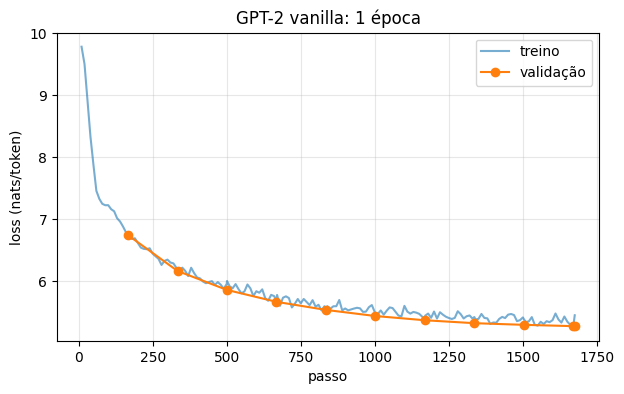

Val loss final: 5.278 | perplexidade: 196.0 | BPB: 1.522

>>> Nos últimos anos, a partir da população, a partir da pesquisa, a partir da pesquisa, a pesquisa, a pesquisa, a pesquisa, a pesquisa, a pesquisa, a pesquisa, a pesquisa, a pesquisa, a

>>> Este trabalho tem como objetivo geral, a partir de uma vez que a partir de uma vez que se faz necessário a sociedade, a partir da sociedade, a partir de uma vez que se faz com a partir de uma vez que

>>> No contexto brasileiro, a partir da pesquisa, a pesquisa, a pesquisa, a partir da pesquisa, a pesquisa, a pesquisa, a pesquisa, a pesquisa, a pesquisa, a pesquisa, a pesquisa, a pesquisa,


In [26]:
import matplotlib.pyplot as plt
import pandas as pd

log = pd.read_csv(os.path.join(WORK_DIR, "vanilla_log.csv"))
val = log.dropna(subset=["val_loss"])

plt.figure(figsize=(7, 4))
plt.plot(log["passo"], log["train_loss"], label="treino", alpha=0.6)
plt.plot(val["passo"], val["val_loss"], "o-", label="validação")
plt.xlabel("passo"); plt.ylabel("loss (nats/token)"); plt.legend(); plt.grid(alpha=0.3)
plt.title("GPT-2 vanilla: 1 época")
plt.savefig(os.path.join(WORK_DIR, "vanilla_curva.png"), dpi=150, bbox_inches="tight")
plt.show()

ultima = val.iloc[-1]
print(f"Val loss final: {ultima.val_loss:.3f} | perplexidade: {math.exp(ultima.val_loss):.1f} | BPB: {ultima.val_bpb:.3f}")

base = getattr(model, "_orig_mod", model).eval()
for p in ["Nos últimos anos,", "Este trabalho tem como objetivo", "No contexto brasileiro,"]:
    ids = torch.tensor([tokenizer.encode(p)], device=device)
    out = generate_text_simple(base, ids, max_new_tokens=40, context_size=GPT_CONFIG["context_length"])
    print(f"\n>>> {tokenizer.decode(out[0].tolist())}")

In [2]:
  from google.colab import drive, files
  import zipfile, glob, os

  drive.mount('/content/drive')
  WORK_DIR = "/content/drive/MyDrive/Atividade1_checkpoints"
  arquivos = glob.glob(f"{WORK_DIR}/*.csv") + glob.glob(f"{WORK_DIR}/*.png")
  print("\n".join(os.path.basename(a) for a in arquivos))
  with zipfile.ZipFile("/content/logs.zip", "w") as z:
      for a in arquivos:
          z.write(a, os.path.basename(a))
  files.download("/content/logs.zip")


Mounted at /content/drive
bench_fp16_log.csv
bench_fp32_log.csv
bench_sdpa_log.csv
bench_fused_log.csv
bench_otimizacoes.csv
bench_compile_log.csv
vanilla_log.csv
vanilla_curva.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>